# 📘 6.3 Romberg Integration and Richardson Extrapolation

### Improving a numerical estimate by cancelling its leading error

Notebook 6.2 showed that composite trapezoidal error behaves approximately like
$C h^2$ for a sufficiently smooth function. If the same integral is calculated
on two related grids, that predictable error pattern can be used rather than
merely observed.

**Richardson extrapolation** combines estimates at $h$ and $h/2$ to cancel a
leading error term. **Romberg integration** repeats that idea in a structured
table built from nested trapezoidal estimates.

The goal is not to make every integral look complicated. It is to understand how
a carefully organised refinement sequence can produce a much better estimate
from reusable samples.


## Before you begin: read the pattern, not just the equations

This notebook contains subscripts, powers and a triangular table. The notation
records a simple process:

1. calculate the same integral on a coarse grid and a finer grid;
2. use the known error pattern to combine those two answers;
3. repeat with successively finer nested grids; and
4. check whether the improved estimates are settling.

We continue to use $I$ for the ideal integral. It is known for our mathematical
and synthetic verification examples, but it is usually unavailable for a real
experiment. Romberg integration can reduce **quadrature error** under the right
assumptions; it cannot reveal an unknown physical truth or repair poor data.

You do not need to memorise the full Romberg recurrence immediately. Focus first
on what each table entry combines, why the denominator is $4^j-1$, and whether
the samples satisfy the method's requirements.

Romberg integration is most useful when a smooth function is sampled on an
equally spaced, nested grid and high quadrature accuracy is valuable. It is not
automatically the best choice for irregular measurements, noisy sensors,
unresolved features or a question that does not concern accumulation.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* explain Richardson extrapolation as cancellation of a leading error term;
* combine two estimates when their leading order $p$ is known;
* explain why extrapolated trapezoidal estimates reproduce Simpson's rule;
* construct and interpret a Romberg table;
* use `scipy.integrate.romb` with valid sampled data;
* recognise the $2^k+1$ equally spaced sample requirement;
* use successive diagonal changes as a convergence indicator, not true error;
* assess computational cost and sample reuse; and
* recognise situations where extrapolation is unreliable or inappropriate.

### 🔗 Unit Learning Outcome Alignment

This notebook supports:

* **LO1:** Assess the suitability and limitations of numerical analysis tools.
* **LO2:** Develop defensible solutions to open-ended engineering problems.
* **LO3:** Evaluate numerical performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* NIST DLMF — [Romberg integration](https://dlmf.nist.gov/3.5#iii)
* SciPy — [`integrate.romb`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.romb.html)
* SciPy — [Integrating using samples](https://docs.scipy.org/doc/scipy/tutorial/integrate.html#integrating-using-samples)


## 📂 6.3.0 How to use this notebook

This is a **pre-work content notebook**. Run every cell from top to bottom; no
cell requires editing or typed input. The optional control at the end changes
only a displayed refinement level.

Notebook 6.3 improves Newton–Cotes estimates through extrapolation. Notebook 6.4
will take a different approach by choosing Gaussian quadrature nodes and weights.


### 📖 Core language for 6.3

* **Extrapolation** estimates a limiting value using a known trend in approximate
  results.
* **Leading error term** is the dominant term in an error expansion for small $h$.
* **Nested grids** share old nodes when the spacing is halved.
* **Richardson extrapolation** cancels a leading $C h^p$ error term using two
  related estimates.
* A **Romberg table** applies Richardson extrapolation repeatedly to composite
  trapezoidal estimates.
* A table **row** adds a finer trapezoidal grid; a **column** adds one level of
  extrapolation.
* The **main diagonal** contains the most highly extrapolated entry in each row.
* A **successive diagonal change** measures agreement between adjacent diagonal
  entries; it is not automatically the true error.


In [ ]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import quad, romb, simpson, trapezoid

pd.set_option("display.precision", 10)
plt.rcParams["figure.figsize"] = (8.5, 5.0)


## 📂 6.3.1 The Richardson idea

Suppose an approximation $Q(h)$ has leading error order $p$:

$$
Q(h)=I+C h^p+\text{higher-order terms}.
$$

Halving the spacing gives

$$
Q(h/2)=I+C\left(\frac{h}{2}\right)^p+\text{higher-order terms}.
$$

These are **two approximations of the same integral**:

* $Q(h)$ is calculated on the coarser grid;
* $Q(h/2)$ is calculated after halving the spacing; and
* both are trying to estimate the same ideal value $I$.

The same unknown coefficient $C$ appears in both error expressions. To see what
"combining" them means, first multiply the fine-grid equation by $2^p$:

$$
2^pQ(h/2)=2^pI+C h^p+\text{higher-order terms}.
$$

Now subtract the coarse-grid equation $Q(h)=I+C h^p+\cdots$. The matching
$C h^p$ terms cancel:

$$
2^pQ(h/2)-Q(h)
\approx (2^p-1)I.
$$

Dividing by $2^p-1$ gives an approximation of $I$. We call this new numerical
approximation $Q_{\mathrm{R}}$, where the subscript $\mathrm{R}$ means
**Richardson-extrapolated**:

$$
Q_{\mathrm{R}}
=Q(h/2)+\frac{Q(h/2)-Q(h)}{2^p-1}
=\frac{2^pQ(h/2)-Q(h)}{2^p-1}.
$$

We have **not replaced or renamed $I$**. The symbols have different roles:

* $I$ remains the ideal value of the integral;
* $Q(h)$ is the coarse-grid numerical approximation;
* $Q(h/2)$ is the fine-grid numerical approximation; and
* $Q_{\mathrm{R}}$ is the improved numerical approximation formed from both.

In other words, $Q_{\mathrm{R}}\approx I$; they are not assumed to be exactly
equal.

So "combining" means scaling and subtracting the coarse and fine answers so that
their leading errors cancel. It does not mean combining two different integrals.
The finer estimate is corrected in the direction suggested by the change from
coarse to fine. This is not ordinary averaging: one coefficient is negative
because the leading error is being removed.


### A first calculation with $e^x$

For the composite trapezoidal rule, $p=2$. Therefore

$$
Q_{\mathrm{R}}=T(h/2)+\frac{T(h/2)-T(h)}{3}
=\frac{4T(h/2)-T(h)}{3}.
$$

We integrate $e^x$ on $[0,1]$, where $I=e-1$ is known. The coarse grid has two
intervals and the fine grid has four.


,Estimate,Value,Absolute error
0,"T(h), 2 intervals",1.7539310925,0.0356492640
1,"T(h/2), 4 intervals",1.7272219046,0.0089400761
2,Richardson result,1.7183188419,0.0000370135


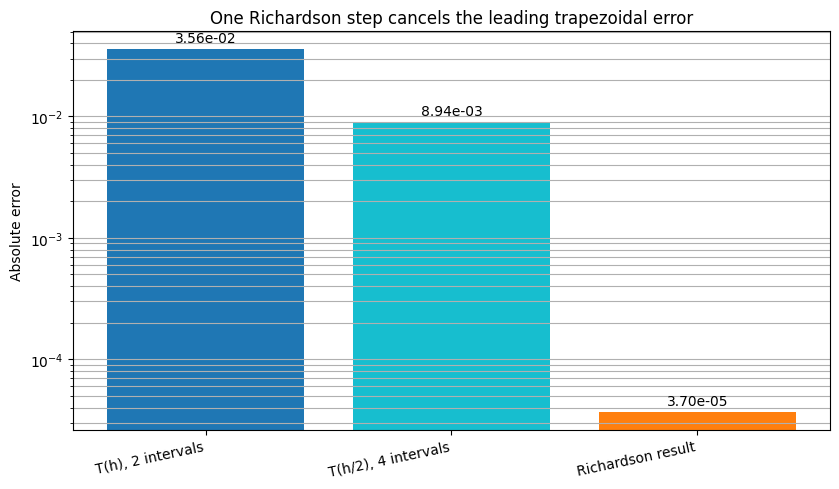

In [ ]:
exact_exp = np.e - 1.0

x_coarse = np.linspace(0.0, 1.0, 3)  # 2 intervals
x_fine = np.linspace(0.0, 1.0, 5)    # 4 intervals

trap_coarse = trapezoid(np.exp(x_coarse), x=x_coarse)
trap_fine = trapezoid(np.exp(x_fine), x=x_fine)
richardson_first = (4.0 * trap_fine - trap_coarse) / 3.0

first_extrapolation = pd.DataFrame(
    {
        "Estimate": ["T(h), 2 intervals", "T(h/2), 4 intervals", "Richardson result"],
        "Value": [trap_coarse, trap_fine, richardson_first],
        "Absolute error": [
            abs(exact_exp - trap_coarse),
            abs(exact_exp - trap_fine),
            abs(exact_exp - richardson_first),
        ],
    }
)
display(first_extrapolation)

fig, ax = plt.subplots()
bars = ax.bar(
    first_extrapolation["Estimate"],
    first_extrapolation["Absolute error"],
    color=["tab:blue", "tab:cyan", "tab:orange"],
)
ax.set_yscale("log")
ax.set_ylabel("Absolute error")
ax.set_title("One Richardson step cancels the leading trapezoidal error")
ax.grid(True, axis="y", which="both")
ax.bar_label(bars, fmt="%.2e", padding=3)
plt.xticks(rotation=12, ha="right")
plt.tight_layout()
plt.show()


The Richardson result is much more accurate, but it still is not exact for
$e^x$. Cancellation removes the leading $h^2$ term; higher-order terms remain.

Richardson extrapolation depends on the assumed $p$. If the function is not
sufficiently smooth or the calculation is not in its asymptotic range, the
assumed error pattern may not describe the estimates well.


## 📂 6.3.2 The Simpson connection

The first Richardson extrapolation of two nested composite trapezoidal estimates
is algebraically the composite Simpson 1/3 rule on the fine grid:

$$
R_{1,1}=\frac{4T(h/2)-T(h)}{3}=S(h/2).
$$

This explains why the first extrapolated column improves from second-order to
fourth-order behaviour. Simpson's rule is not appearing by coincidence; it is
the first structured cancellation of trapezoidal error.


In [ ]:
simpson_fine = simpson(np.exp(x_fine), x=x_fine)

connection = pd.DataFrame(
    {
        "Calculation": ["Richardson from two trapezoidal grids", "Simpson on fine grid"],
        "Value": [richardson_first, simpson_fine],
        "Difference": [richardson_first - simpson_fine, 0.0],
    }
)
display(connection)
print("Numerically equal?", np.isclose(richardson_first, simpson_fine))


,Calculation,Value,Difference
0,Richardson from two trapezoidal grids,1.7183188419,-4.4408920985e-16
1,Simpson on fine grid,1.7183188419,0.0000000000e+00


Numerically equal? True


## 📂 6.3.3 Why the assumed order matters

A general Richardson helper needs the leading order $p$:

$$
Q_{\mathrm{R}}=Q(h/2)+\frac{Q(h/2)-Q(h)}{2^p-1}.
$$

Supplying $p=4$ to a genuinely second-order trapezoidal pair under-corrects the
estimate. Supplying a theoretical order does not force the data to behave that
way.


In [ ]:
def richardson_extrapolate(coarse, fine, order):
    if order <= 0:
        raise ValueError("order must be positive")
    return fine + (fine - coarse) / (2.0**order - 1.0)


order_comparison = []
for assumed_order in [1, 2, 4, 6]:
    estimate = richardson_extrapolate(trap_coarse, trap_fine, assumed_order)
    order_comparison.append(
        {
            "Assumed p": assumed_order,
            "Extrapolated estimate": estimate,
            "Absolute error": abs(exact_exp - estimate),
        }
    )

display(pd.DataFrame(order_comparison))


,Assumed p,Extrapolated estimate,Absolute error
0,1,1.7005127167,0.0177691118
1,2,1.7183188419,0.0000370135
2,4,1.7254412920,0.0071594636
3,6,1.7267979492,0.0085161207


## 📂 6.3.4 From one correction to a Romberg table

For a sufficiently smooth integrand, the composite trapezoidal estimate has an
even-power error expansion:

$$
T(h)=I+c_1h^2+c_2h^4+c_3h^6+\cdots.
$$

Romberg integration uses spacings

$$h_k=\frac{b-a}{2^k}$$

and constructs entries $R_{k,j}$:

$$
R_{k,0}=T(h_k),
$$

$$
R_{k,j}=R_{k,j-1}
+\frac{R_{k,j-1}-R_{k-1,j-1}}{4^j-1},
\qquad j=1,\ldots,k.
$$

* Column 0 contains trapezoidal estimates.
* Column 1 cancels the $h^2$ term and matches Simpson-level estimates.
* Column 2 cancels the next $h^4$ term.
* Each move to the right assumes enough smoothness for another error term.


In [ ]:
def romberg_table_from_samples(y, dx):
    y = np.asarray(y, dtype=float)
    intervals = y.size - 1
    levels = int(np.log2(intervals))

    if intervals < 1 or 2**levels != intervals:
        raise ValueError("sample count must equal 2**k + 1")
    if dx <= 0:
        raise ValueError("dx must be positive")

    table = np.full((levels + 1, levels + 1), np.nan)

    # Each row uses a nested subset of the finest supplied grid.
    for row in range(levels + 1):
        stride = 2 ** (levels - row)
        y_row = y[::stride]
        dx_row = dx * stride
        table[row, 0] = trapezoid(y_row, dx=dx_row)

        for column in range(1, row + 1):
            table[row, column] = table[row, column - 1] + (
                table[row, column - 1] - table[row - 1, column - 1]
            ) / (4.0**column - 1.0)

    return table


x_romberg = np.linspace(0.0, 1.0, 17)  # 16 = 2**4 intervals
y_romberg = np.exp(x_romberg)
table_exp = romberg_table_from_samples(y_romberg, dx=x_romberg[1] - x_romberg[0])

labels = [f"R[:,{column}]" for column in range(table_exp.shape[1])]
romberg_dataframe = pd.DataFrame(table_exp, columns=labels)
romberg_dataframe.index = [f"{2**row} intervals" for row in range(table_exp.shape[0])]
display(romberg_dataframe)


,"R[:,0]","R[:,1]","R[:,2]","R[:,3]","R[:,4]"
1 intervals,1.8591409142,NaN,NaN,NaN,NaN
2 intervals,1.7539310925,1.7188611519,NaN,NaN,NaN
4 intervals,1.7272219046,1.7183188419,1.7182826879,NaN,NaN
8 intervals,1.7205185922,1.7182841547,1.7182818422,1.7182818288,NaN
16 intervals,1.7188411286,1.7182819741,1.7182818287,1.7182818285,1.7182818285


### Reading the table

Read the table in three directions:

* **down column 0:** the trapezoidal grid is refined;
* **right across a row:** another leading error term is cancelled; and
* **down the main diagonal:** both refinement and extrapolation depth increase.

The lower-right entry uses all 17 samples and four extrapolation levels. Entries
outside the triangle do not exist because row $k$ can support only columns
$0,\ldots,k$.


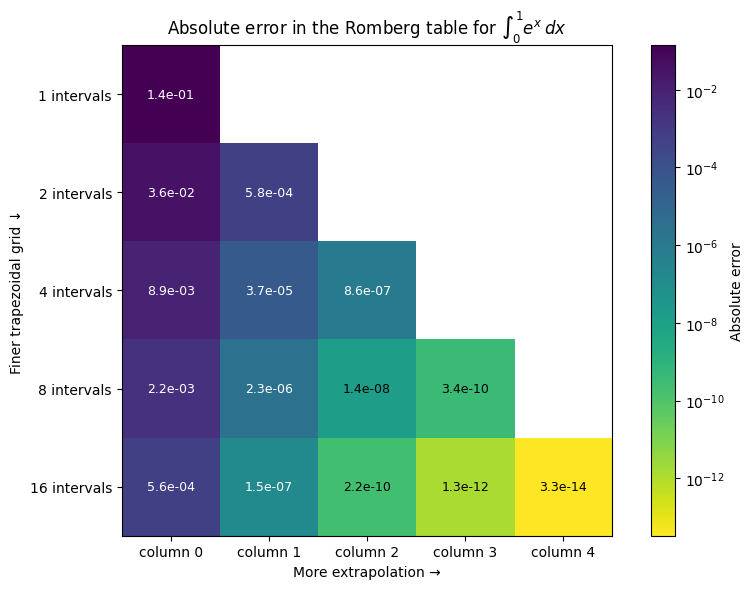

In [ ]:
table_errors = np.abs(table_exp - exact_exp)
masked_errors = np.ma.masked_invalid(table_errors)

fig, ax = plt.subplots(figsize=(8.5, 6.0))
image = ax.imshow(masked_errors, cmap="viridis_r", norm="log")

for row in range(table_exp.shape[0]):
    for column in range(row + 1):
        ax.text(
            column,
            row,
            f"{table_errors[row, column]:.1e}",
            ha="center",
            va="center",
            color="white" if table_errors[row, column] > 1e-7 else "black",
            fontsize=9,
        )

ax.set_xticks(range(table_exp.shape[1]), [f"column {j}" for j in range(table_exp.shape[1])])
ax.set_yticks(range(table_exp.shape[0]), [f"{2**k} intervals" for k in range(table_exp.shape[0])])
ax.set_xlabel("More extrapolation →")
ax.set_ylabel("Finer trapezoidal grid ↓")
ax.set_title(r"Absolute error in the Romberg table for $\int_0^1e^x\,dx$")
fig.colorbar(image, ax=ax, label="Absolute error")
plt.tight_layout()
plt.show()


The heatmap makes the algorithm's purpose visible: accuracy generally improves
down and to the right. This smooth verification function is favourable to
Romberg integration. Real sampled data may not show such orderly behaviour.


## 📂 6.3.5 Nested grids reuse previous samples

The interval counts are $1,2,4,8,\ldots$. When spacing is halved, every coarse
node remains on the fine grid. Only the midpoint of each old interval is new.

With $2^k$ intervals, the finest grid contains

$$N=2^k+1$$

samples, including both endpoints. This explains SciPy's `2**k + 1` input
requirement for `romb`.


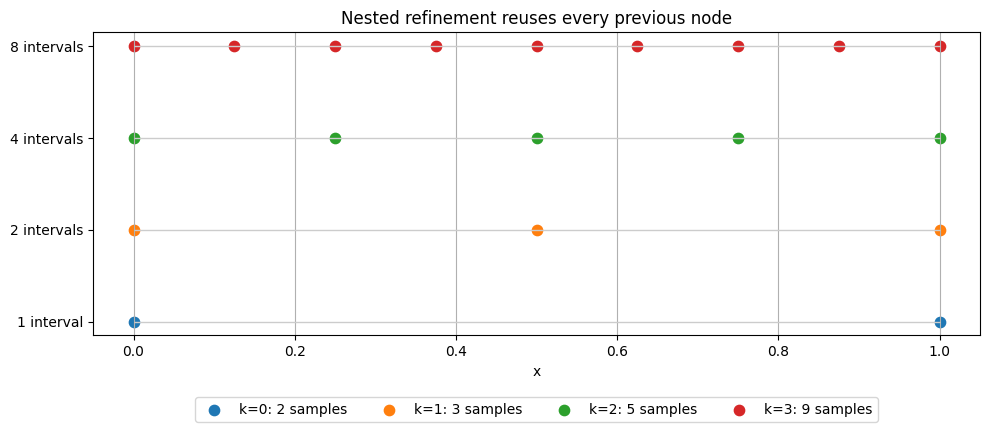

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
levels_to_show = 4

for level in range(levels_to_show):
    nodes = np.linspace(0.0, 1.0, 2**level + 1)
    ax.scatter(nodes, np.full_like(nodes, level), s=55, label=f"k={level}: {nodes.size} samples")
    ax.hlines(level, 0.0, 1.0, color="0.8", linewidth=1)

ax.set_yticks(range(levels_to_show), ["1 interval", "2 intervals", "4 intervals", "8 intervals"])
ax.set_xlabel("x")
ax.set_title("Nested refinement reuses every previous node")
ax.grid(True, axis="x")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4)
plt.tight_layout()
plt.show()


Sample reuse is valuable when function evaluations are expensive or when a test
plan can be designed in stages. It does not mean a coarse completed experiment
can always be refined later: the new midpoint measurements must actually exist
or be collected.


## 📂 6.3.6 Using SciPy's sampled-data Romberg function

`scipy.integrate.romb(y, dx=...)` accepts:

* sample values `y`;
* one constant positive spacing `dx`;
* an optional integration `axis`; and
* `show=True` for SciPy's printed one-dimensional extrapolation table.

Unlike `trapezoid` and `simpson`, `romb` does not accept an `x` coordinate array.
Equal spacing is therefore an input responsibility, not something SciPy can
infer from coordinates.


In [ ]:
scipy_romberg = romb(y_romberg, dx=x_romberg[1] - x_romberg[0])
manual_romberg = table_exp[-1, -1]

scipy_comparison = pd.DataFrame(
    {
        "Calculation": ["Manual Romberg table", "scipy.integrate.romb", "Exact e - 1"],
        "Value": [manual_romberg, scipy_romberg, exact_exp],
        "Absolute error": [
            abs(exact_exp - manual_romberg),
            abs(exact_exp - scipy_romberg),
            0.0,
        ],
    }
)
display(scipy_comparison)
print("Manual and SciPy agree?", np.isclose(manual_romberg, scipy_romberg))


,Calculation,Value,Absolute error
0,Manual Romberg table,1.7182818285,3.3306690739e-14
1,scipy.integrate.romb,1.7182818285,3.3306690739e-14
2,Exact e - 1,1.7182818285,0.0000000000e+00


Manual and SciPy agree? True


### Validating the sample count before calling `romb`

A small input check gives a clearer message than relying on a downstream error.
The bitwise expression below is true only when the interval count is a positive
power of two.


In [ ]:
def has_romberg_sample_count(values):
    intervals = np.asarray(values).size - 1
    return intervals > 0 and (intervals & (intervals - 1)) == 0


sample_count_check = pd.DataFrame(
    {
        "Samples": [5, 9, 11, 17, 33],
        "Intervals": [4, 8, 10, 16, 32],
        "Valid for romb": [
            has_romberg_sample_count(np.zeros(count))
            for count in [5, 9, 11, 17, 33]
        ],
    }
)
display(sample_count_check)


,Samples,Intervals,Valid for romb
0,5,4,True
1,9,8,True
2,11,10,False
3,17,16,True
4,33,32,True


## 📂 6.3.7 Engineering return: rocket-motor total impulse

We again estimate

$$
I_{\mathrm{total}}=\int_0^{10}F(t)\,\mathrm{d}t.
$$

The synthetic generating function provides a mathematical reference for
verification. A 65-sample grid has 64 intervals, so it supports a complete
Romberg table with levels $k=0,\ldots,6$.


In [ ]:
def underlying_thrust_N(time_s):
    time_s = np.asarray(time_s, dtype=float)
    burn_duration_s = 10.0
    rise = 1.0 - np.exp(-2.8 * time_s)
    decay = 1.0 - np.exp(-2.2 * (burn_duration_s - time_s))
    modulation = 1.0 + 0.035 * np.sin(1.25 * time_s)
    thrust = 1180.0 * rise * decay * modulation
    return np.where((time_s >= 0.0) & (time_s <= burn_duration_s), thrust, 0.0)


impulse_reference, _ = quad(
    lambda time_s: float(underlying_thrust_N(time_s)),
    0.0,
    10.0,
    epsabs=1e-10,
)

time_65 = np.linspace(0.0, 10.0, 65)
thrust_65 = underlying_thrust_N(time_65)
dx_65 = time_65[1] - time_65[0]
rocket_table = romberg_table_from_samples(thrust_65, dx=dx_65)

rocket_estimates = pd.DataFrame(
    {
        "Method": ["Trapezoidal", "Simpson", "Romberg", "Synthetic reference"],
        "Impulse [N s]": [
            trapezoid(thrust_65, x=time_65),
            simpson(thrust_65, x=time_65),
            romb(thrust_65, dx=dx_65),
            impulse_reference,
        ],
    }
)
rocket_estimates["Absolute error [N s]"] = abs(
    rocket_estimates["Impulse [N s]"] - impulse_reference
)
display(rocket_estimates)


,Method,Impulse [N s],Absolute error [N s]
0,Trapezoidal,10833.8166911668,11.9599851107
1,Simpson,10845.6532675593,0.1234087182
2,Romberg,10845.7760245797,0.0006516977
3,Synthetic reference,10845.7766762775,0.0000000000


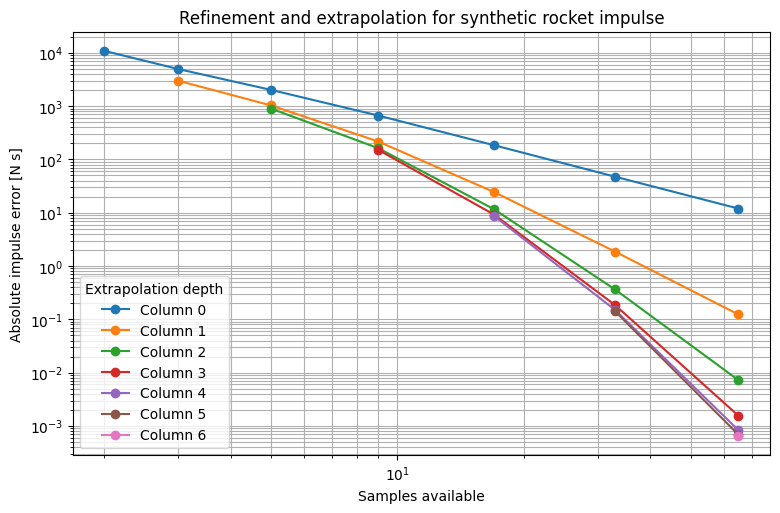

In [ ]:
rocket_errors = np.abs(rocket_table - impulse_reference)

fig, ax = plt.subplots(figsize=(9.0, 5.5))
for column in range(rocket_table.shape[1]):
    valid_rows = np.arange(column, rocket_table.shape[0])
    sample_numbers = 2**valid_rows + 1
    ax.loglog(
        sample_numbers,
        rocket_errors[valid_rows, column],
        marker="o",
        label=f"Column {column}",
    )

ax.set_xlabel("Samples available")
ax.set_ylabel("Absolute impulse error [N s]")
ax.set_title("Refinement and extrapolation for synthetic rocket impulse")
ax.grid(True, which="both")
ax.legend(title="Extrapolation depth")
plt.show()


The curve for column 0 shows trapezoidal refinement. Moving to higher columns
adds extrapolation. On this smooth synthetic example, the most extrapolated
values become accurate quickly.

This comparison is possible only because the generating function is known. For
a real thrust test, the table can show numerical settling but cannot supply an
independent physical truth.


## 📂 6.3.8 What the diagonal means when $I$ is unknown

In the rocket example, the first diagonal entry is zero. The one-interval grid
sees only ignition and burnout, where the synthetic thrust is zero, and misses
the entire burn between them. The algorithm has not failed; the coarse samples
contain almost no useful information.

Let

$$D_k=R_{k,k}$$

denote the main-diagonal estimate. A practical convergence indicator is

$$
\Delta_k=|D_k-D_{k-1}|.
$$

A combined absolute and relative criterion can be written as

$$
\Delta_k\leq \tau_{\mathrm{abs}}+
\tau_{\mathrm{rel}}|D_k|.
$$

This checks whether adjacent diagonal estimates agree within a stated tolerance.
It does **not** prove that $|I-D_k|\leq\Delta_k$ unless additional assumptions
justify that interpretation.


In [ ]:
rocket_diagonal = np.diag(rocket_table)
diagonal_change = np.r_[np.nan, np.abs(np.diff(rocket_diagonal))]

absolute_tolerance = 0.1   # N s
relative_tolerance = 1e-5
threshold = absolute_tolerance + relative_tolerance * np.abs(rocket_diagonal)
criterion_met = diagonal_change <= threshold

diagonal_report = pd.DataFrame(
    {
        "Level k": np.arange(rocket_diagonal.size),
        "Samples": 2 ** np.arange(rocket_diagonal.size) + 1,
        "Diagonal estimate [N s]": rocket_diagonal,
        "Successive change [N s]": diagonal_change,
        "Tolerance threshold [N s]": threshold,
        "Criterion met": criterion_met,
    }
)
display(diagonal_report)


,Level k,Samples,Diagonal estimate [N s],Successive change [N s],Tolerance threshold [N s],Criterion met
0,0,2,0.0000000000,NaN,0.1000000000,False
1,1,3,7857.3935545863,7857.3935545863,0.1785739355,False
2,2,5,9951.3283482672,2093.9347936809,0.1995132835,False
3,3,9,10695.1211113259,743.7927630587,0.2069512111,False
4,4,17,10837.1229480284,142.0018367025,0.2083712295,False
5,5,33,10845.6341231915,8.5111751631,0.2084563412,False
6,6,65,10845.7760245797,0.1419013883,0.2084577602,True


A stopping criterion is meaningful only when its tolerances follow from the
engineering decision. A tolerance of 0.1 N s may be irrelevant if sensor
calibration uncertainty is 100 N s, or inadequate if a downstream safety margin
is much smaller.


## 📂 6.3.9 Accuracy versus sample cost

At level $k$, the nested grid uses $2^k+1$ total samples. Moving from level $k-1$
to $k$ requires $2^{k-1}$ new midpoint samples.

The Romberg arithmetic is inexpensive compared with collecting experimental data
or evaluating a costly simulation. The real efficiency gain comes from reusing
previous samples and obtaining higher-order estimates from the same finest grid.


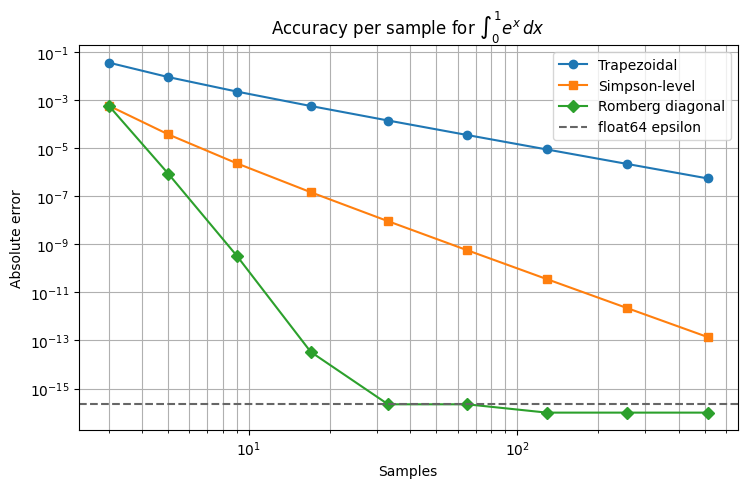

In [ ]:
cost_rows = []
for level in range(1, 10):
    x = np.linspace(0.0, 1.0, 2**level + 1)
    y = np.exp(x)
    table = romberg_table_from_samples(y, dx=x[1] - x[0])
    cost_rows.append(
        {
            "Samples": x.size,
            "Trapezoidal error": abs(exact_exp - table[-1, 0]),
            "Simpson-level error": abs(exact_exp - table[-1, 1]),
            "Romberg diagonal error": abs(exact_exp - table[-1, -1]),
        }
    )

cost_study = pd.DataFrame(cost_rows)

fig, ax = plt.subplots()
for column, marker in [
    ("Trapezoidal error", "o"),
    ("Simpson-level error", "s"),
    ("Romberg diagonal error", "D"),
]:
    ax.loglog(
        cost_study["Samples"],
        np.maximum(cost_study[column], 1e-16),
        marker=marker,
        label=column.replace(" error", ""),
    )

ax.axhline(np.finfo(float).eps, color="0.4", linestyle="--", label="float64 epsilon")
ax.set_xlabel("Samples")
ax.set_ylabel("Absolute error")
ax.set_title(r"Accuracy per sample for $\int_0^1e^x\,dx$")
ax.grid(True, which="both")
ax.legend()
plt.show()


The Romberg diagonal reaches floating-point limits quickly for this exceptionally
smooth function. More extrapolation cannot produce unlimited accuracy. Once
round-off or data error dominates, additional refinement may provide no benefit.


## 📂 6.3.10 Irregular coordinates are not valid `romb` input

`romb` accepts `y` and one constant `dx`; it has no `x` parameter. Passing values
collected at irregular coordinates together with an average spacing silently
asks SciPy to integrate them **as though they were equally spaced**.

The calculation may run, but it represents the wrong geometry. Use a method that
accepts the actual coordinates, redesign the grid, or justify a separate
resampling procedure.


,Calculation,Value,Absolute error
0,Trapezoidal with actual x coordinates,1.7224877440,0.0042059155
1,romb after incorrectly assuming constant dx,1.5464924425,0.1717893860
2,Exact mathematical integral,1.7182818285,0.0000000000


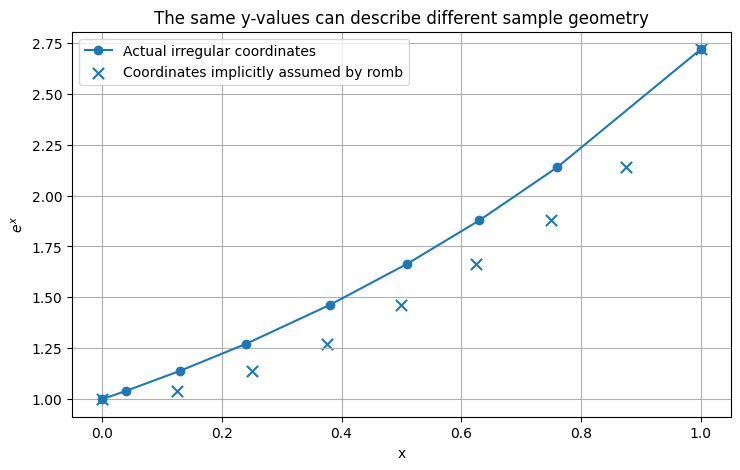

In [ ]:
x_irregular = np.array([0.00, 0.04, 0.13, 0.24, 0.38, 0.51, 0.63, 0.76, 1.00])
y_irregular = np.exp(x_irregular)

actual_coordinate_estimate = trapezoid(y_irregular, x=x_irregular)
wrongly_assumed_dx = (x_irregular[-1] - x_irregular[0]) / (x_irregular.size - 1)
misleading_romberg = romb(y_irregular, dx=wrongly_assumed_dx)

irregular_comparison = pd.DataFrame(
    {
        "Calculation": [
            "Trapezoidal with actual x coordinates",
            "romb after incorrectly assuming constant dx",
            "Exact mathematical integral",
        ],
        "Value": [actual_coordinate_estimate, misleading_romberg, exact_exp],
        "Absolute error": [
            abs(exact_exp - actual_coordinate_estimate),
            abs(exact_exp - misleading_romberg),
            0.0,
        ],
    }
)
display(irregular_comparison)

fig, ax = plt.subplots()
ax.plot(x_irregular, y_irregular, "o-", label="Actual irregular coordinates")
ax.scatter(
    np.linspace(0.0, 1.0, x_irregular.size),
    y_irregular,
    marker="x",
    s=65,
    label="Coordinates implicitly assumed by romb",
)
ax.set_xlabel("x")
ax.set_ylabel(r"$e^x$")
ax.set_title("The same y-values can describe different sample geometry")
ax.grid(True)
ax.legend()
plt.show()


## 📂 6.3.11 Extrapolation can amplify data defects

Richardson extrapolation forms weighted differences. This is powerful when the
differences follow the expected smooth truncation-error expansion. A biased or
corrupted measurement does not follow that expansion and may influence several
entries in the table.

The example below adds a modest 20 N error to one thrust sample. The table still
produces precise-looking numbers, but extra columns do not remove the faulty
measurement.


,Level,Samples,Clean diagonal [N s],Corrupted diagonal [N s],Change caused by one sample [N s]
0,0,2,0.0000000000,0.0000000000,0.0000000000
1,1,3,7857.3935545863,7990.7268879196,133.3333333333
2,2,5,9951.3283482672,9977.9950149338,26.6666666667
3,3,9,10695.1211113259,10710.5003000384,15.3791887125
4,4,17,10837.1229480284,10844.7469754171,7.6240273887
5,5,33,10845.6341231915,10849.4425490394,3.8084258479
6,6,65,10845.7760245797,10847.6797723592,1.9037477794


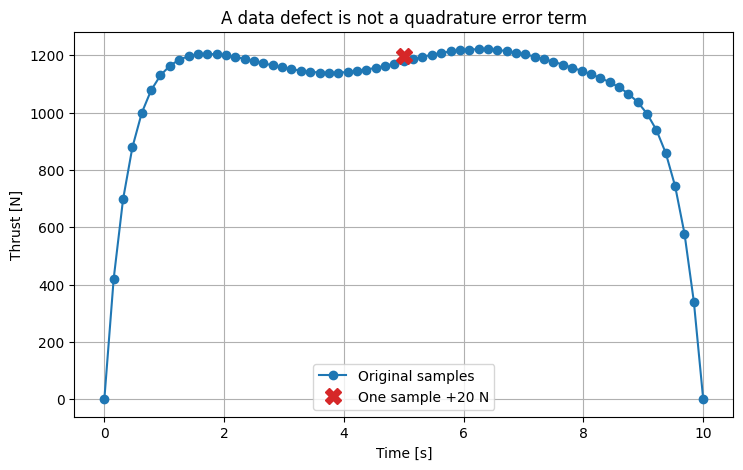

In [ ]:
thrust_corrupted = thrust_65.copy()
corrupted_index = 32  # the midpoint appears in every grid after level 0
thrust_corrupted[corrupted_index] += 20.0
corrupted_table = romberg_table_from_samples(thrust_corrupted, dx=dx_65)

comparison_rows = []
for level in range(rocket_table.shape[0]):
    comparison_rows.append(
        {
            "Level": level,
            "Samples": 2**level + 1,
            "Clean diagonal [N s]": rocket_table[level, level],
            "Corrupted diagonal [N s]": corrupted_table[level, level],
            "Change caused by one sample [N s]": abs(
                corrupted_table[level, level] - rocket_table[level, level]
            ),
        }
    )

corruption_comparison = pd.DataFrame(comparison_rows)
display(corruption_comparison)

fig, ax = plt.subplots()
ax.plot(time_65, thrust_65, "o-", label="Original samples")
ax.plot(
    time_65[corrupted_index],
    thrust_corrupted[corrupted_index],
    "X",
    markersize=11,
    color="tab:red",
    label="One sample +20 N",
)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Thrust [N]")
ax.set_title("A data defect is not a quadrature error term")
ax.grid(True)
ax.legend()
plt.show()


The appropriate response is to investigate data quality, calibration and
repeatability—not to add extrapolation columns until the table looks stable.


## 📂 6.3.12 Method selection

| Situation | Romberg suitability | Reason |
|---|---|---|
| Smooth callable model on a finite interval | Often strong | nested evaluations and even-power error expansion are plausible |
| Equally spaced $2^k+1$ high-quality samples | Suitable to investigate | matches `romb` input structure |
| Irregular experimental coordinates | Poor without justified preprocessing | no single `dx` represents the samples |
| Noisy or biased sensor data | Use cautiously | extrapolation does not remove data error |
| Discontinuity, corner or singularity | Often poor across the feature | smooth error expansion may fail |
| Unresolved oscillation or narrow peak | Unsafe | missing physical information cannot be extrapolated |
| Only one coarse sample set | Not available | nested refinement estimates are missing |

Romberg integration is one option, not the default destination of every
integration problem.


## 📂 6.3.13 Optional interactive table depth

Move the slider to reveal successive Romberg levels for
$\int_0^1e^x\,\mathrm{d}x$. The displayed table uses only samples available at
the selected level.


In [ ]:
def display_romberg_level(level=3):
    x = np.linspace(0.0, 1.0, 2**level + 1)
    table = romberg_table_from_samples(np.exp(x), dx=x[1] - x[0])
    frame = pd.DataFrame(
        table,
        columns=[f"column {j}" for j in range(table.shape[1])],
        index=[f"k={k}" for k in range(table.shape[0])],
    )
    display(frame)
    print(f"Diagonal estimate: {table[-1, -1]:.12f}")
    print(f"Absolute verification error: {abs(exact_exp - table[-1, -1]):.3e}")


try:
    import ipywidgets as widgets

    widgets.interact(
        display_romberg_level,
        level=widgets.IntSlider(
            value=3,
            min=1,
            max=7,
            step=1,
            description="Level k",
            continuous_update=False,
        ),
    )
except ImportError:
    print("ipywidgets is unavailable; showing level k=3.")
    display_romberg_level(level=3)


interactive(children=(IntSlider(value=3, continuous_update=False, description='Level k', max=7, min=1), Output…

## 📂 6.3.14 Common interpretation failures

| Failure | Why it is unsafe | Better action |
|---|---|---|
| Treating diagonal change as exact error | $I$ is still unknown | call it a convergence indicator |
| Using the wrong $p$ in Richardson extrapolation | cancellation targets the wrong pattern | verify the observed order and assumptions |
| Passing irregular samples to `romb` | `dx` assumes equal spacing | preserve and inspect actual coordinates |
| Interpolating to manufacture $2^k+1$ samples | no new physical information is created | collect valid samples or report preprocessing limits |
| Assuming more columns always help | noise and round-off can dominate | monitor table behaviour and data quality |
| Ignoring units in tolerances | numerical agreement may be irrelevant | connect tolerances to engineering decisions |
| Calling a synthetic reference ground truth | the function was designed, not independently measured | describe it as model verification evidence |


## 📂 6.3.15 Useful packages and functions

| Package | Function or technique | Purpose | Important caution |
|---|---|---|---|
| `scipy.integrate` | `romb` | Romberg integration of sampled values | requires $2^k+1$ equally spaced samples |
| `scipy.integrate` | `trapezoid` | build or verify column 0 | pass actual coordinates when available |
| `scipy.integrate` | `simpson` | verify the first extrapolated column | classical connection assumes nested equal grids |
| NumPy | `log2`, powers of two | validate nested sample counts | check integer logic before slicing |
| NumPy | `diag`, `diff`, `isclose` | inspect diagonals and agreement | agreement is not physical truth |
| pandas | `DataFrame` | display triangular tables and reports | labels should distinguish estimates from errors |
| Matplotlib | `imshow`, `loglog` | visualise table error and convergence | log axes require positive magnitudes |


## 📂 6.3.16 Engineering workflow and summary

A defensible Richardson/Romberg workflow is:

1. confirm that integration answers the engineering question;
2. inspect the function or measurements for smoothness and resolved features;
3. confirm equal spacing and a $2^k+1$ sample count;
4. build or inspect the nested trapezoidal sequence;
5. apply Richardson cancellation using the justified leading order;
6. interpret the Romberg table by rows, columns and diagonal;
7. compare successive diagonal entries using physically meaningful tolerances;
8. verify the implementation on a known smooth integral;
9. assess measurement and modelling uncertainty separately; and
10. report the estimate, sampling structure, convergence evidence and limitations.

**Key result:** Richardson extrapolation combines $Q(h)$ and $Q(h/2)$ to cancel
a leading $C h^p$ error term. Romberg integration repeatedly applies this idea to
nested trapezoidal estimates. Its high accuracy is conditional on smoothness,
valid equally spaced samples and trustworthy data.


## 📚 References

* NIST Digital Library of Mathematical Functions, *Romberg Integration*, Section 3.5(iii).
* SciPy developers, *`scipy.integrate.romb`*, stable documentation.
* SciPy developers, *Integrating using samples*, user guide.

## 🤖 AI Acknowledgment

Generative AI was used to help structure explanations, develop deterministic
teaching examples and review code. The teaching team remains responsible for the
mathematics, engineering interpretation, source selection and final notebook.
